In [1]:
from utils import DQN, ReplayBuffer, greedy_action, epsilon_greedy, update_target, loss

import torch
from torch import nn
import torch.nn.functional as F
import torch.optim as optim
import math
import numpy as np

import gym
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

Training the optimized DQN

In [2]:
# optimized hyperparameters

NUM_RUNS = 10
# training details
batch_size = 32
## optimizer parameters
lr = 0.001
beta1 = 0.9
beta2=0.99

optimisation_freq = 4

# exploration rate
epsilon_start = 1  # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1

# replay
replay_memory_size = 20000 
replay_start_size = batch_size 

# target update
update_frequency = 4 

# discount factor
gamma = 1

# architecture
net_arc = [4,64,64,2]





In [3]:
runs_results = []

env = gym.make('CartPole-v1')
for run in range(NUM_RUNS):
    print(f"Starting run {run+1} of {NUM_RUNS}")
    policy_net = DQN(net_arc)
    target_net = DQN(net_arc)
    update_target(target_net, policy_net)
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(beta1, beta2))
    memory = ReplayBuffer(replay_memory_size)

    steps_done = 0

    episode_durations = []
    EPSILON = epsilon_start
    for i_episode in range(300):
        if (i_episode+1) % 50 == 0:
            print("episode ", i_episode+1, "/", 300)

        observation, info = env.reset()
        state = torch.tensor(observation).float()

        done = False
        terminated = False
        t = 0
        while not (done or terminated):

            # Select and perform an action
            action = epsilon_greedy(EPSILON, policy_net, state)

            observation, reward, done, terminated, info = env.step(action)
            reward = torch.tensor([reward])
            action = torch.tensor([action])
            next_state = torch.tensor(observation).reshape(-1).float()

            memory.push([state, action, next_state, reward, torch.tensor([done])])

            # Move to the next state
            state = next_state

            # Perform one step of the optimization (on the policy network)
            if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                transitions = memory.sample(batch_size)
                state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                # Compute loss
                mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                # Optimize the model
                optimizer.zero_grad()
                mse_loss.backward()
                optimizer.step()
            
            if done or terminated:
                episode_durations.append(t + 1)
            t += 1
            steps_done+=1
        # Update the target network, copying all weights and biases in DQN
        if i_episode % update_frequency == 0: 
            update_target(target_net, policy_net)
        # if i_episode% 50 ==0:
        #     print(EPSILON)
        if EPSILON>epsilon_stop: ############### need to change
            EPSILON = EPSILON * epsilon_decay
        else:
            EPSILON = epsilon_stop
    runs_results.append(episode_durations)
print('Complete')

Starting run 1 of 10


/Users/ioanalazar/opt/anaconda3/envs/rl/lib/python3.11/site-packages/gym/utils/passive_env_checker.py:233: DeprecationWarning: `np.bool8` is a deprecated alias for `np.bool_`.  (Deprecated NumPy 1.24)
  if not isinstance(terminated, (bool, np.bool8)):


episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 6 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 7 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 8 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episod

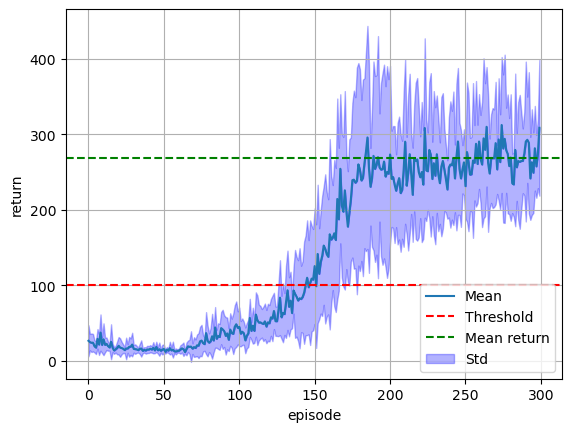

tensor(269.3960)


In [4]:
# Plotting the learning curve
# Placeholder plot, you are free to modify it
 
results = torch.tensor(runs_results)
means = results.float().mean(0)
stds = results.float().std(0)
final_mean =(means[-51:-1]).float().mean(0)
plt.plot(torch.arange(300), means,label='Mean')
plt.axhline(y=100, color='red', linestyle='--', label='Threshold')
plt.axhline(y=final_mean, color='green', linestyle='--', label='Mean return')
plt.ylabel("return")
plt.xlabel("episode")
plt.fill_between(np.arange(300), means, means+stds, alpha=0.3, color='b', label='Std')
plt.fill_between(np.arange(300), means, means-stds, alpha=0.3, color='b')
plt.legend(loc='lower right')
plt.grid()
plt.show()
print(final_mean)

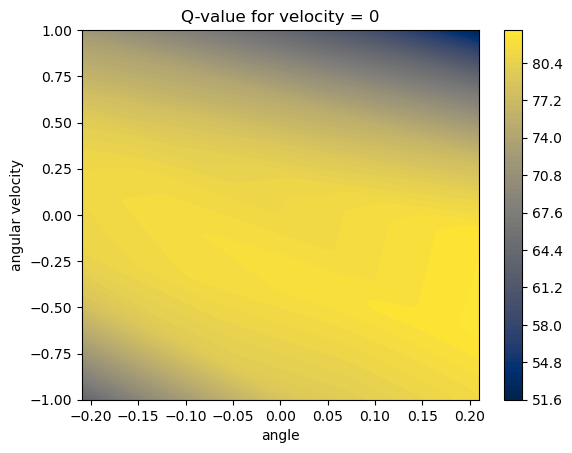

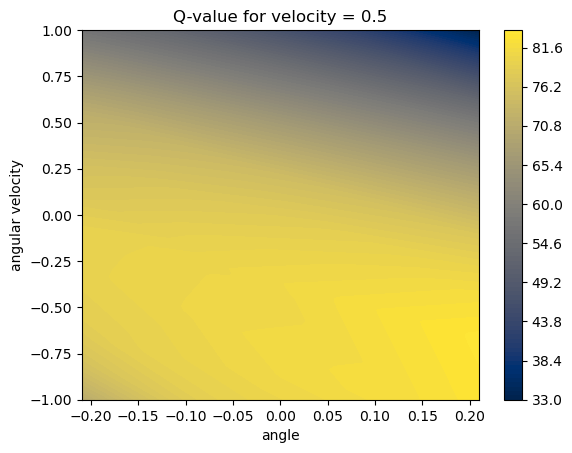

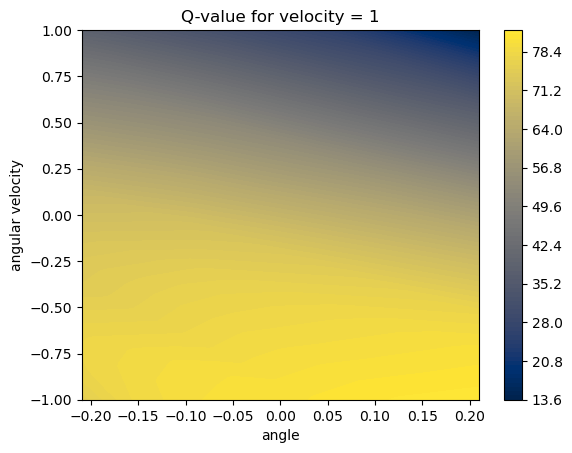

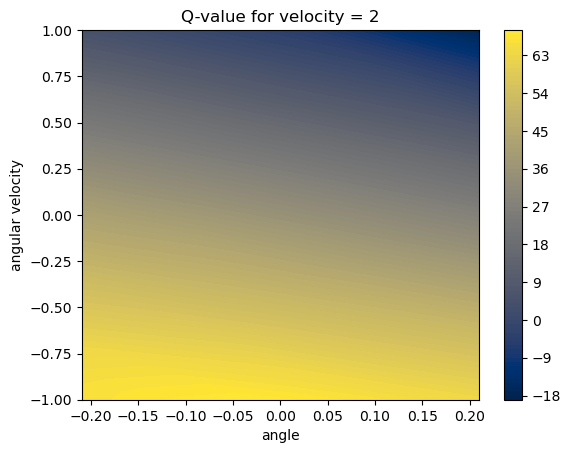

[0. 1.]


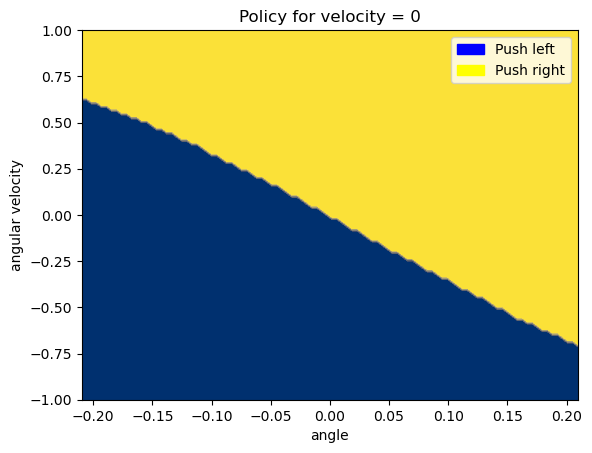

[0. 1.]


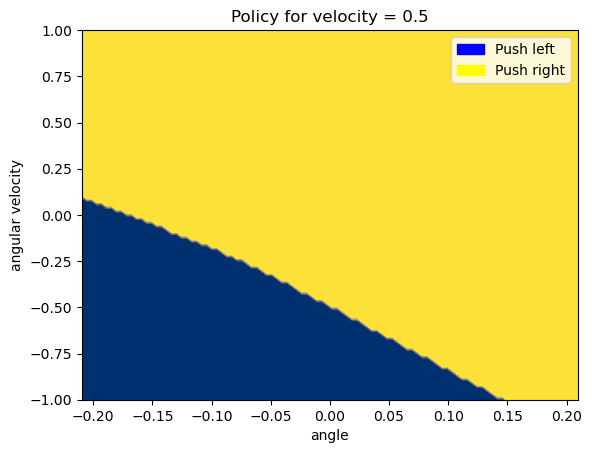

[0. 1.]


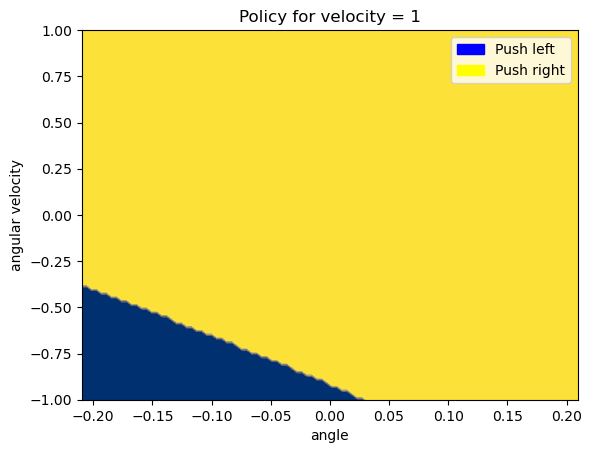

[1.]


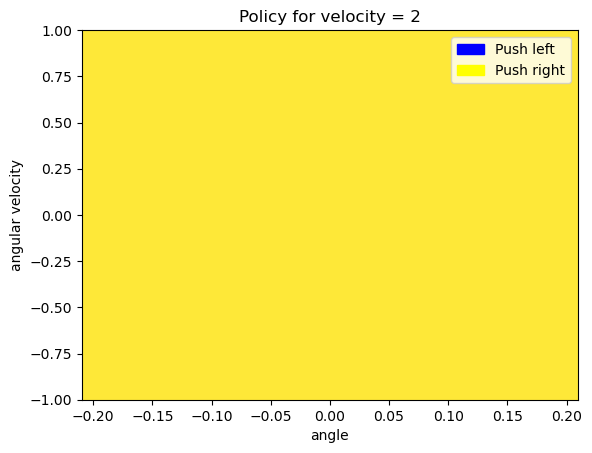

In [5]:
# Visualising the greedy Q-values for a stationary cart in the middle of the track
# 2D plot showing policy as a function of pole angle and angular velocity (omega)

# This plots the policy and Q values according to the network currently
# stored in the variable "policy_net"

# All visualisations provided here are placeholders and you can modify these plots

# Make sure to include appropriate labels and/or legends when presenting your plot
#q = True  # whether q values or greedy policy is visualised

angle_range = .2095 # you may modify this range
omega_range = 1     # you may modify this range

angle_samples = 100
omega_samples = 100
angles = torch.linspace(angle_range, -angle_range, angle_samples)
omegas = torch.linspace(-omega_range, omega_range, omega_samples)
for q in [True, False]:
    for velocity in [0,0.5,1,2]:
        greedy_q_array = torch.zeros((angle_samples, omega_samples))
        policy_array = torch.zeros((angle_samples, omega_samples))
        for i, angle in enumerate(angles):
            for j, omega in enumerate(omegas):
                state = torch.tensor([0., velocity, angle, omega])
                with torch.no_grad():
                    q_vals = policy_net(state)
                    greedy_action = q_vals.argmax()
                    greedy_q_array[i, j] = q_vals[greedy_action]
                    policy_array[i, j] = greedy_action
        if q:
            plt.contourf(angles, omegas, greedy_q_array.T, cmap='cividis', levels=100)
            plt.title("Q-value for velocity = "+ str(velocity))
            plt.colorbar()
        else:
            print(np.unique(policy_array))
            plt.contourf(angles, omegas, policy_array.T, cmap='cividis',vmin=0,vmax=1)
            plt.title("Policy for velocity = "+ str(velocity))

            left_patch = mpatches.Patch(color='blue', label='Push left')
            right_patch = mpatches.Patch(color='yellow', label='Push right')
            plt.legend(handles=[left_patch, right_patch], loc='upper right')
        

        plt.xlabel("angle")
        plt.ylabel("angular velocity")
        plt.show()

Varying one hyperparameter at a time

In [6]:
# fixed set of values
NUM_RUNS = 10
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 # try 20000 
update_frequency = 2
batch_size = 32
gamma = 1
replay_start_size = batch_size 
net_arc = [4,64,64,2]
optimisation_freq = 1


Learning rate

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

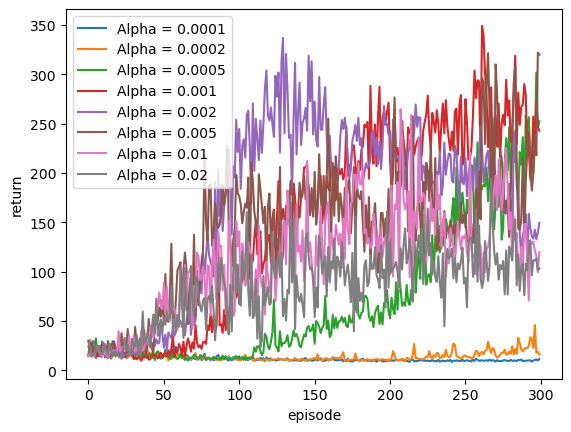

In [7]:
# hyperparameter exploration
NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size # maybe try batch siz

gamma = 1
# architecture
net_arc = [4,64,64,2]
optimisation_freq = 4
alpha_list = [0.0001, 0.0002,0.0005,0.001,0.002,0.005,0.01,0.02] 
for lr in alpha_list:
    runs_results = []

    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(beta1, beta2))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma, policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Alpha = {lr}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Batch size

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

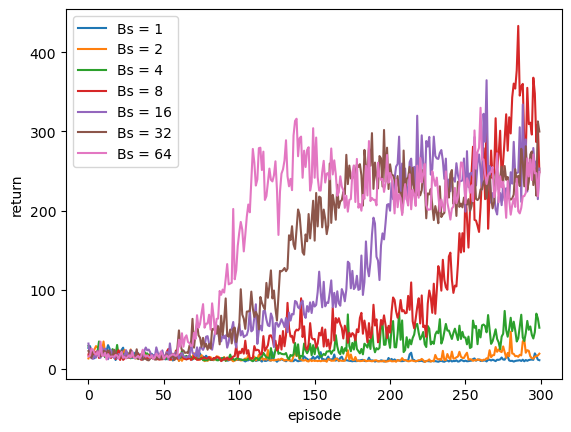

In [8]:
# hyperparameter exploration
NUM_RUNS = 5
epsilon_start = 0.9 
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size 

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4

batch_size_list = [1,2,4,8,16,32,64]
for batch_size in batch_size_list:
    runs_results = []
    replay_start_size = batch_size 
    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(beta1, beta2))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Bs = {batch_size}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Betas (Adam)

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

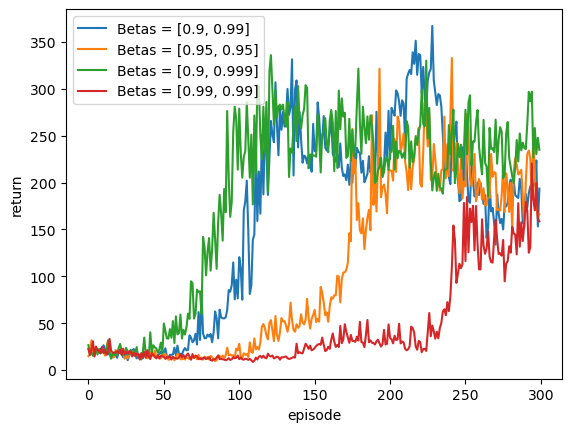

In [9]:
# hyperparameter exploration

NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 # try 20000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size # maybe try batch siz
gamma = 1
# architecture
net_arc = [4,64,64,2]
optimisation_freq = 4
betas_list =[[0.9,0.99],[0.95,0.95],[0.9,0.999],[0.99,0.99]]
for betas in betas_list:
    runs_results = []
    replay_start_size = batch_size 
    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        net_arc = [4]+[size_hidden_layer for _ in range(n_hidden_layers)]+[2] ##
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Betas = {str(betas)}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Target update frequency

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

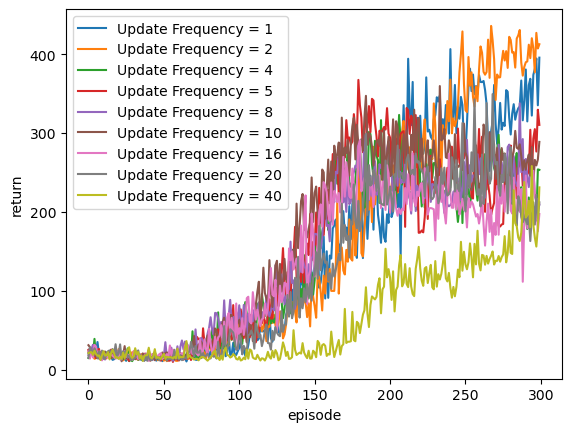

In [10]:
# explore target_update

NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 # try 20000 
update_frequency = 5
batch_size = 32
# discount factor
replay_start_size = batch_size # maybe try batch siz

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4
betas =[0.9,0.99]
update_frequency_list = [1,2,4,5,8,10,16,20,40]
replay_start_size = batch_size 
for update_frequency in update_frequency_list:
    runs_results = []
    
    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Update Frequency = {update_frequency}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Optimisation frequency

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

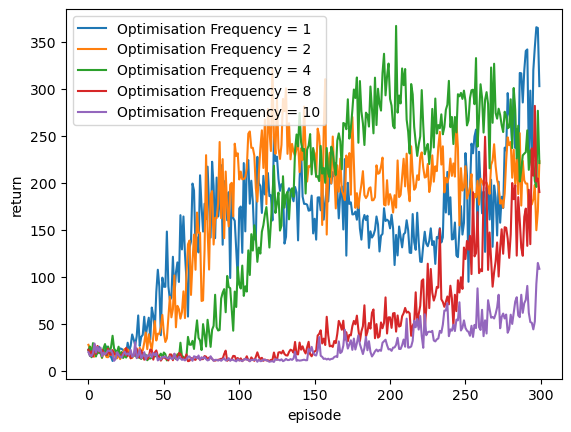

In [11]:
# explore target_update

NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size
betas = [0.9,0.999]
gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4
optimisation_freq_list = [1,2,4,8,10]
             
for optimisation_freq in optimisation_freq_list:
    runs_results = []

    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Optimisation Frequency = {optimisation_freq}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Replay buffer size 


Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

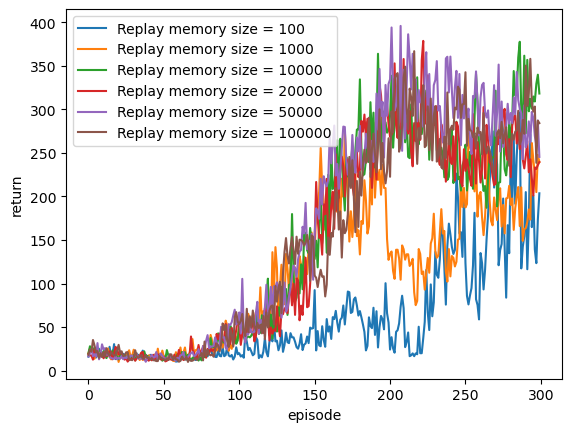

In [12]:
# explore target_update


betas =[0.9,0.99]

NUM_RUNS = 5
epsilon_start = 0.9 
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size 
gamma = 1
# architecture

net_arc = [4,64,64,2]
optimisation_freq = 4
replay_memory_size_list = [100, 1000, 10000, 20000,50000,100000]
             
for replay_memory_size in replay_memory_size_list:
    runs_results = []

    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Replay memory size = {replay_memory_size}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Network architecture

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

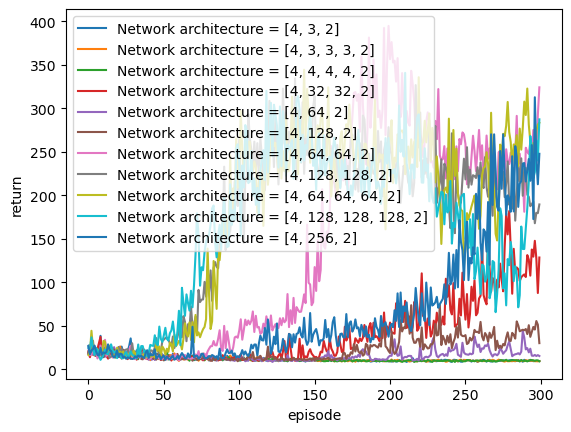

In [13]:
# explore target_update
NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 
update_frequency = 5
batch_size = 32
replay_start_size = batch_size 

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4
net_arc_list = [[4,3,2],[4,3,3,3,2],[4,4,4,4,2],[4,32,32,2],[4,64,2],[4,128,2],[4,64,64,2],[4,128,128,2],[4,64,64,64,2],[4,128,128,128,2],[4,256,2]]

betas =[0.9,0.99]
             
for net_arc in net_arc_list:
    runs_results = []

    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'Network architecture = {str(net_arc)}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Gamma

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

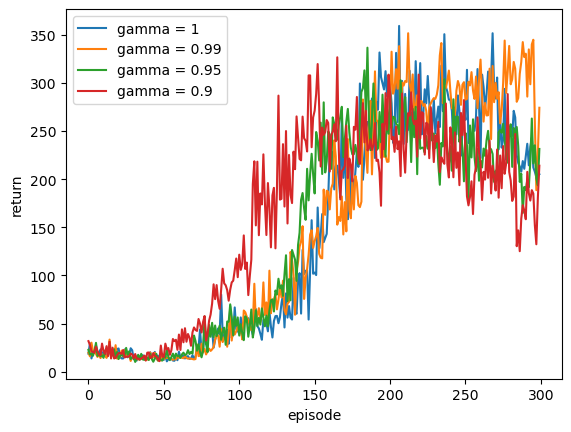

In [14]:
# net arc 2
NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 # try 20000 
update_frequency = 5
batch_size = 32
# discount factor
replay_start_size = batch_size # maybe try batch siz

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4
betas =[0.9,0.99]
gamma_list = [1,0.99,0.95,0.9]



for gamma in gamma_list:
    runs_results = []

    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'gamma = {str(gamma)}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Exploration rate

Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Complete
Starting run 1 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 5
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 5
episode  50 / 300
episode  100 / 300
epi

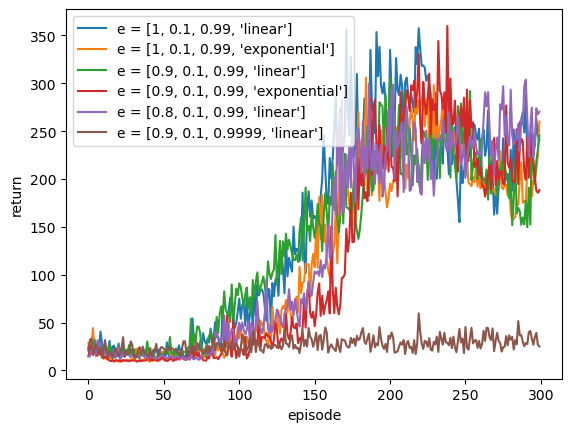

In [15]:
# epsilon
NUM_RUNS = 5
epsilon_start = 0.9 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.999
replay_memory_size = 10000 # try 20000 
update_frequency = 5
batch_size = 32
# discount factor
replay_start_size = batch_size # maybe try batch siz

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4
betas =[0.9,0.99]
epsilon_list = [[1,0.1,0.99,"linear"],[1,0.1,0.99,"exponential"],[0.9,0.1,0.99,"linear"],[0.9,0.1,0.99,"exponential"],[0.8,0.1,0.99,"linear"],[0.9,0.1,0.9999,"linear"]]
for epsilon in epsilon_list:
    runs_results = []
    epsilon_start = epsilon[0]  # placeholder value - you should implement your own exploration schedule
    epsilon_decay = epsilon[2]
    epsilon_stop = epsilon[1]
    env = gym.make('CartPole-v1')
    for run in range(NUM_RUNS):
        print(f"Starting run {run+1} of {NUM_RUNS}")
        policy_net = DQN(net_arc)
        target_net = DQN(net_arc)
        update_target(target_net, policy_net)
        target_net.eval()

        optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(betas[0], betas[1]))
        memory = ReplayBuffer(replay_memory_size)

        steps_done = 0

        episode_durations = []
        EPSILON = epsilon_start
        for i_episode in range(300):
            if (i_episode+1) % 50 == 0:
                print("episode ", i_episode+1, "/", 300)

            observation, info = env.reset()
            state = torch.tensor(observation).float()

            done = False
            terminated = False
            t = 0
            while not (done or terminated):

                # Select and perform an action
                action = epsilon_greedy(EPSILON, policy_net, state)

                observation, reward, done, terminated, info = env.step(action)
                reward = torch.tensor([reward])
                action = torch.tensor([action])
                next_state = torch.tensor(observation).reshape(-1).float()

                memory.push([state, action, next_state, reward, torch.tensor([done])])

                # Move to the next state
                state = next_state

                # Perform one step of the optimization (on the policy network)
                if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                    transitions = memory.sample(batch_size)
                    state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                    # Compute loss
                    mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                    # Optimize the model
                    optimizer.zero_grad()
                    mse_loss.backward()
                    optimizer.step()
                
                if done or terminated:
                    episode_durations.append(t + 1)
                t += 1
                steps_done+=1
            # Update the target network, copying all weights and biases in DQN
            if i_episode % update_frequency == 0: 
                update_target(target_net, policy_net)
            # if i_episode% 50 ==0:
            #     print(EPSILON)
            if EPSILON>epsilon_stop: ############### need to change
                if epsilon[-1] =="exponential":
                    EPSILON = EPSILON * (epsilon_decay**i_episode)
                else:
                    EPSILON = EPSILON * (epsilon_decay)
            else:
                EPSILON = epsilon_stop
        runs_results.append(episode_durations)
    print('Complete')
    results = torch.tensor(runs_results)
    means = results.float().mean(0)
    plt.plot(torch.arange(300), means,label=f'e = {str(epsilon)}')

plt.ylabel("return")  
plt.xlabel("episode")
plt.legend()  
plt.show()

Following this hyperparameter exploration, different combinations of hyperparameters, using the variables found to perform best in the above were run and plot individually, and their learning curve, policy slices and q value slices were compared

Starting run 1 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 2 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 3 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 4 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 5 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 6 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 7 of 10
episode  50 / 300
episode  100 / 300
episode  150 / 300
episode  200 / 300
episode  250 / 300
episode  300 / 300
Starting run 8 of 10
episode  50 / 300
episode  100 / 300
epis

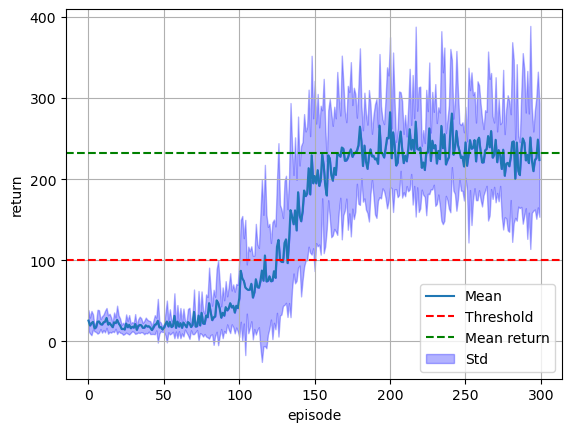

tensor(231.6551)


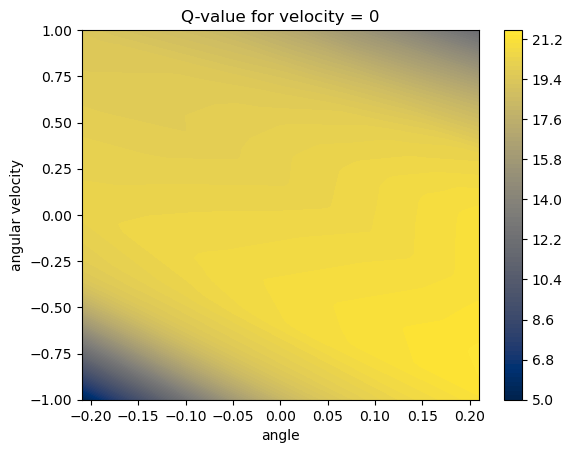

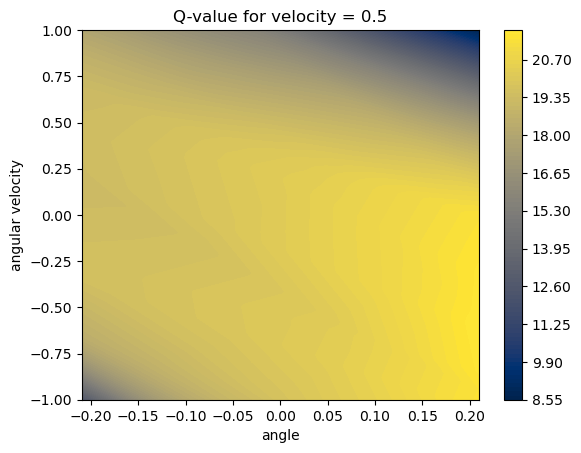

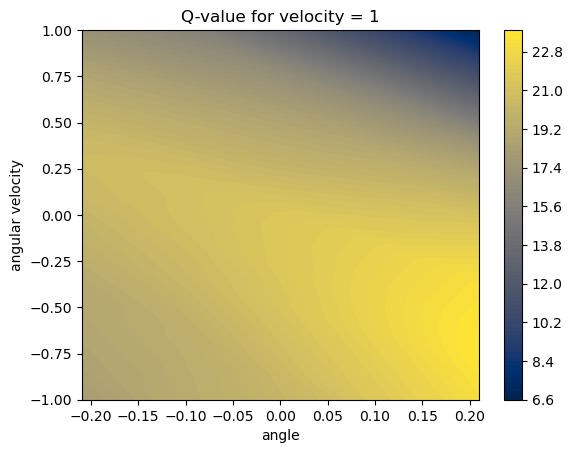

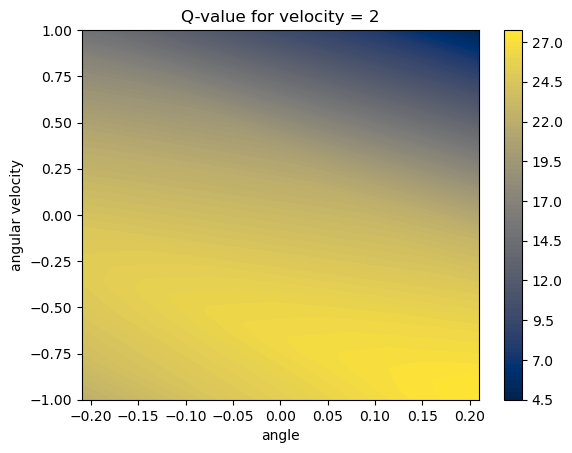

[0. 1.]


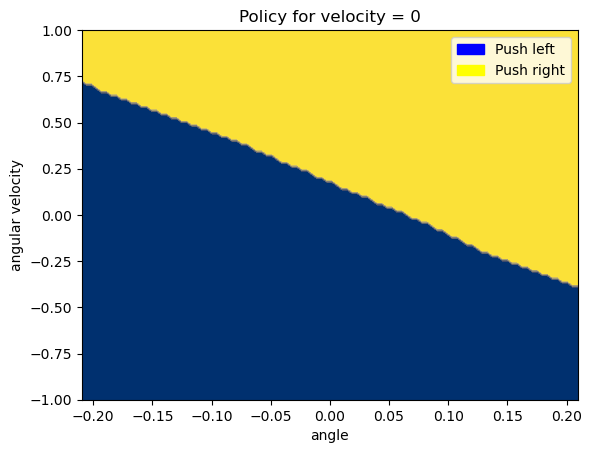

[0. 1.]


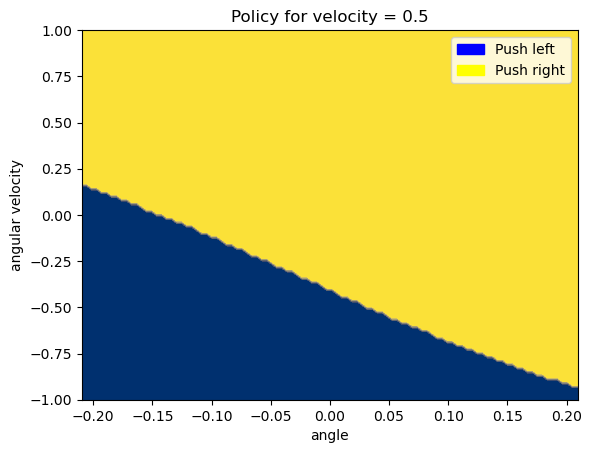

[0. 1.]


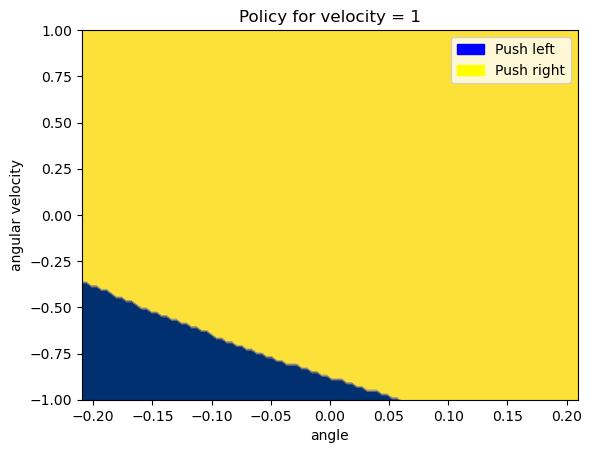

[1.]


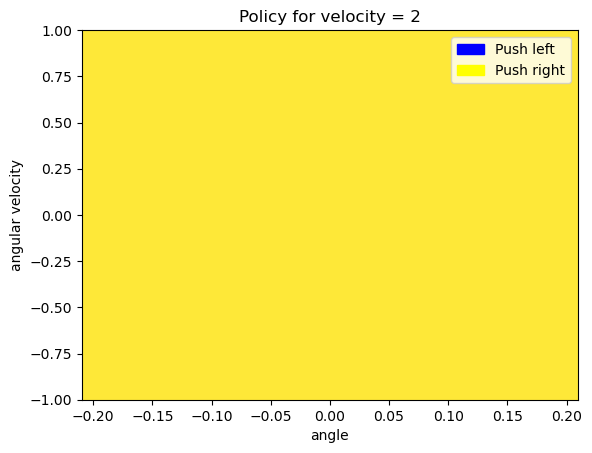

In [16]:
# example output for one combination
NUM_RUNS = 10
epsilon_start = 1 # placeholder value - you should implement your own exploration schedule
epsilon_decay = 0.99
epsilon_stop = 0.1
lr = 0.001
beta1 = 0.9
beta2=0.99
replay_memory_size = 20000 # try 20000 
update_frequency = 16
batch_size = 32
# discount factor
replay_start_size = batch_size 

gamma = 1
# architecture
n_hidden_layers = 3 ## for 1
size_hidden_layer = 64##
net_arc = [4,64,64,2]
optimisation_freq = 4

runs_results = []

env = gym.make('CartPole-v1')
for run in range(NUM_RUNS):
    print(f"Starting run {run+1} of {NUM_RUNS}")
    policy_net = DQN(net_arc)
    target_net = DQN(net_arc)
    update_target(target_net, policy_net)
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=lr, betas=(beta1, beta2))
    memory = ReplayBuffer(replay_memory_size)

    steps_done = 0

    episode_durations = []
    EPSILON = epsilon_start
    for i_episode in range(300):
        if (i_episode+1) % 50 == 0:
            print("episode ", i_episode+1, "/", 300)

        observation, info = env.reset()
        state = torch.tensor(observation).float()

        done = False
        terminated = False
        t = 0
        while not (done or terminated):

            # Select and perform an action
            action = epsilon_greedy(EPSILON, policy_net, state)

            observation, reward, done, terminated, info = env.step(action)
            reward = torch.tensor([reward])
            action = torch.tensor([action])
            next_state = torch.tensor(observation).reshape(-1).float()

            memory.push([state, action, next_state, reward, torch.tensor([done])])

            # Move to the next state
            state = next_state

            # Perform one step of the optimization (on the policy network)
            if not len(memory.buffer) < replay_start_size and steps_done%optimisation_freq==0:
                transitions = memory.sample(batch_size)
                state_batch, action_batch, nextstate_batch, reward_batch, dones = (torch.stack(x) for x in zip(*transitions))
                # Compute loss
                mse_loss = loss(gamma,policy_net, target_net, state_batch, action_batch, reward_batch, nextstate_batch, dones)
                # Optimize the model
                optimizer.zero_grad()
                mse_loss.backward()
                optimizer.step()
            
            if done or terminated:
                episode_durations.append(t + 1)
            t += 1
            steps_done+=1
        # Update the target network, copying all weights and biases in DQN
        if i_episode % update_frequency == 0: 
            update_target(target_net, policy_net)
        # if i_episode% 50 ==0:
        #     print(EPSILON)
        if EPSILON>epsilon_stop: ############### need to change
            EPSILON = EPSILON * epsilon_decay
        else:
            EPSILON = epsilon_stop
    runs_results.append(episode_durations)
print('Complete')
# Plotting the learning curve
# Placeholder plot, you are free to modify it
 
results = torch.tensor(runs_results)
means = results.float().mean(0)
stds = results.float().std(0)
final_mean =(means[-50:-1]).float().mean(0)
plt.plot(torch.arange(300), means,label='Mean')
plt.axhline(y=100, color='red', linestyle='--', label='Threshold')
plt.axhline(y=final_mean, color='green', linestyle='--', label='Mean return')
plt.ylabel("return")
plt.xlabel("episode")
plt.fill_between(np.arange(300), means, means+stds, alpha=0.3, color='b', label='Std')
plt.fill_between(np.arange(300), means, means-stds, alpha=0.3, color='b')
plt.legend(loc='lower right')
plt.grid()
plt.show()
print(final_mean)
# Visualising the greedy Q-values for a stationary cart in the middle of the track
# 2D plot showing policy as a function of pole angle and angular velocity (omega)

# This plots the policy and Q values according to the network currently
# stored in the variable "policy_net"

# All visualisations provided here are placeholders and you can modify these plots

# Make sure to include appropriate labels and/or legends when presenting your plot

policy_net_saved = policy_net   # randomly initialised, replace with your trained DQN
#q = True  # whether q values or greedy policy is visualised

angle_range = .2095 # you may modify this range
omega_range = 1     # you may modify this range

angle_samples = 100
omega_samples = 100
angles = torch.linspace(angle_range, -angle_range, angle_samples)
omegas = torch.linspace(-omega_range, omega_range, omega_samples)
for q in [True, False]:
    for velocity in [0,0.5,1,2]:
        greedy_q_array = torch.zeros((angle_samples, omega_samples))
        policy_array = torch.zeros((angle_samples, omega_samples))
        for i, angle in enumerate(angles):
            for j, omega in enumerate(omegas):
                state = torch.tensor([0., velocity, angle, omega])
                with torch.no_grad():
                    q_vals = policy_net_saved(state)
                    greedy_action = q_vals.argmax()
                    greedy_q_array[i, j] = q_vals[greedy_action]
                    policy_array[i, j] = greedy_action
        if q:
            plt.contourf(angles, omegas, greedy_q_array.T, cmap='cividis', levels=100)
            plt.title("Q-value for velocity = "+ str(velocity))
            plt.colorbar()
        else:
            print(np.unique(policy_array))
            plt.contourf(angles, omegas, policy_array.T, cmap='cividis',vmin=0,vmax=1)
            plt.title("Policy for velocity = "+ str(velocity))

            left_patch = mpatches.Patch(color='blue', label='Push left')
            right_patch = mpatches.Patch(color='yellow', label='Push right')
            plt.legend(handles=[left_patch, right_patch], loc='upper right')
        

        plt.xlabel("angle")
        plt.ylabel("angular velocity")
        plt.show()